05_machine_learning.ipynb

1. Introduction
2. Import Libraries
3. Load Feature-Engineered Dataset
4. Define X and y
5. Train-Test Split
6. Build Preprocessing Pipeline
7. Train Multiple ML Models
8. Evaluate Models
9. Compare Models
10. Select Best Model
11. Confusion Matrix
12. ROC Curve
13. Precision-Recall Curve
14. Feature Importance
15. Test Individual Employee
16. Save Final Model
17. Conclusion

# 05 - Machine Learning

## Employee Attrition Prediction

### Objective

The objective of this notebook is to develop a machine learning model
that predicts whether an employee is likely to leave the organization.

The workflow includes:

1. Preparing features and target variables.
2. Splitting the dataset into training and testing sets.
3. Building a preprocessing pipeline.
4. Training multiple classification algorithms.
5. Evaluating model performance using multiple metrics.
6. Comparing the models.
7. Selecting the best-performing model.
8. Analyzing important features.
9. Saving the final model for deployment.

Since employee attrition is a binary classification problem, the models
will predict two outcomes:

0 = Employee stays
1 = Employee leaves

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import joblib

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

import warnings
warnings.filterwarnings('ignore')

## 2. Loading Feature-Engineered Dataset

The feature-engineered dataset created in the previous notebook
will be used for machine learning.

In [3]:
df = pd.read_csv('../data/feature_engineered_hr_data.csv')

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AgeGroup,IncomeGroup,TenureGroup,RecentlyPromoted,JobLevelGroup,OverallSatisfaction,CompanyExperienceRatio
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,4,0,5,36-45,High,6-10 Years,1,Mid Level,2.00,0.750000
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,7,1,7,46-60,High,6-10 Years,1,Mid Level,3.00,1.000000
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,0,0,0,36-45,Low,0-2 Years,1,Entry Level,3.00,0.000000
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,7,3,0,26-35,Low,6-10 Years,0,Entry Level,3.25,1.000000
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,2,2,2,26-35,Medium,0-2 Years,1,Entry Level,2.50,0.333333


## 3. Defining Features and Target

The target variable is `Attrition`.

The feature matrix contains employee characteristics that may be
associated with attrition.

EmployeeNumber is excluded because it is an identifier and does not
represent meaningful employee characteristics.

In [4]:
X = df.drop(columns=['Attrition', 'EmployeeNumber'], errors='ignore')

y = df['Attrition']

In [5]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1470, 37)
y shape: (1470,)


In [6]:
print(y.value_counts())

Attrition
0    1233
1     237
Name: count, dtype: int64


In [7]:
print(y.value_counts(normalize=True) * 100)

Attrition
0    83.877551
1    16.122449
Name: proportion, dtype: float64


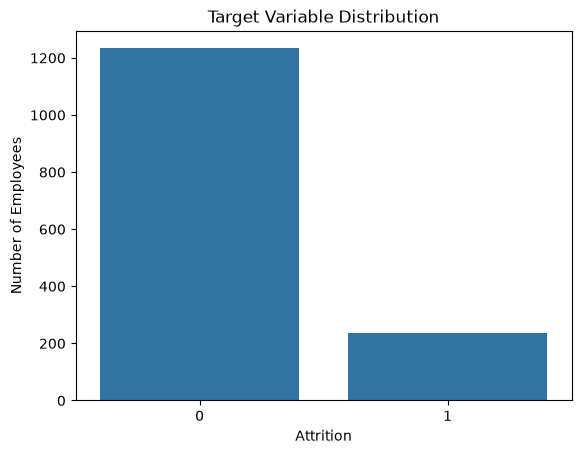

In [9]:
sns.countplot(x=y)

plt.title('Target Variable Distribution')
plt.xlabel('Attrition')
plt.ylabel('Number of Employees')
plt.show()

### Observation

The target variable is imbalanced because the number of employees
who stayed is considerably higher than the number of employees who
left.

Therefore, accuracy alone will not be sufficient for evaluating the
models.

Precision, Recall, F1-score, ROC-AUC and PR-AUC will also be considered.

In [10]:
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'RecentlyPromoted', 'OverallSatisfaction', 'CompanyExperienceRatio']

Categorical features:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime', 'AgeGroup', 'IncomeGroup', 'TenureGroup', 'JobLevelGroup']


## 4. Train-Test Split

The dataset is divided into training and testing sets.

The training dataset will be used to train the models, while the
testing dataset will be used to evaluate their performance on
unseen data.

Stratification is used to preserve the proportion of attrition
classes in both datasets.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [12]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1176, 37)
Testing data: (294, 37)


In [13]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training target distribution:
Attrition
0    0.838435
1    0.161565
Name: proportion, dtype: float64

Testing target distribution:
Attrition
0    0.840136
1    0.159864
Name: proportion, dtype: float64


## 5. Building Preprocessing Pipeline

The dataset contains both numerical and categorical variables.

Numerical variables are standardized using StandardScaler.

Categorical variables are converted into numerical representations
using OneHotEncoder.

A ColumnTransformer is used to apply the appropriate preprocessing
to each feature type.

The preprocessing is included inside the machine learning pipeline
to prevent data leakage.

In [14]:
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ]
)

In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

## 6. Model 1 - Logistic Regression

Logistic Regression is used as a baseline classification model.

It is simple, interpretable, and suitable for binary classification.

In [16]:
logistic_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(
            max_iter=1000,
            class_weight='balanced',
            random_state=42
        ))
    ]
)

In [17]:
logistic_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](37,)","['Age','BusinessTravel','DailyRate',...,'JobLevelGroup', 'OverallSatisfaction','CompanyExperienceRatio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,37
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying 

In [18]:
y_pred_lr = logistic_pipeline.predict(X_test)

y_prob_lr = logistic_pipeline.predict_proba(X_test)[:, 1]

## 7. Model 2 - Decision Tree

Decision Tree is a tree-based classification algorithm that
learns decision rules from employee characteristics.

In [19]:
decision_tree_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeClassifier(
            max_depth=5,
            min_samples_leaf=5,
            class_weight='balanced',
            random_state=42
        ))
    ]
)

In [20]:
decision_tree_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](37,)","['Age','BusinessTravel','DailyRate',...,'JobLevelGroup', 'OverallSatisfaction','CompanyExperienceRatio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,37
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying 

In [21]:
y_pred_dt = decision_tree_pipeline.predict(X_test)

y_prob_dt = decision_tree_pipeline.predict_proba(X_test)[:, 1]

## 8. Model 3 - Random Forest

Random Forest is an ensemble learning algorithm that combines
multiple decision trees.

It can capture nonlinear relationships between employee
characteristics and attrition.

In [22]:
random_forest_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestClassifier(
            n_estimators=300,
            max_depth=10,
            min_samples_leaf=3,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [23]:
random_forest_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](37,)","['Age','BusinessTravel','DailyRate',...,'JobLevelGroup', 'OverallSatisfaction','CompanyExperienceRatio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,37
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying 

In [24]:
y_pred_rf = random_forest_pipeline.predict(X_test)

y_prob_rf = random_forest_pipeline.predict_proba(X_test)[:, 1]

## 9. Model 4 - Gradient Boosting

Gradient Boosting builds models sequentially, where each new model
attempts to correct errors made by previous models.

It is included to compare another powerful tree-based approach.

In [25]:
gradient_boosting_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ))
    ]
)

In [26]:
gradient_boosting_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](37,)","['Age','BusinessTravel','DailyRate',...,'JobLevelGroup', 'OverallSatisfaction','CompanyExperienceRatio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,37
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying 

In [27]:
y_pred_gb = gradient_boosting_pipeline.predict(X_test)

y_prob_gb = gradient_boosting_pipeline.predict_proba(X_test)[:, 1]

## 10. Model Evaluation

Since employee attrition is an imbalanced classification problem,
multiple evaluation metrics are used.

### Metrics

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC

Recall is particularly important because failing to identify an
employee who may leave can be costly for HR planning.

In [28]:
def evaluate_model(model_name, y_true, y_pred, y_prob):

    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

In [29]:
results = []

results.append(
    evaluate_model(
        'Logistic Regression',
        y_test,
        y_pred_lr,
        y_prob_lr
    )
)

results.append(
    evaluate_model(
        'Decision Tree',
        y_test,
        y_pred_dt,
        y_prob_dt
    )
)

results.append(
    evaluate_model(
        'Random Forest',
        y_test,
        y_pred_rf,
        y_prob_rf
    )
)

results.append(
    evaluate_model(
        'Gradient Boosting',
        y_test,
        y_pred_gb,
        y_prob_gb
    )
)

In [30]:
results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.782313,0.400000,0.723404,0.515152,0.842364,0.590378
1,Decision Tree,0.748299,0.324675,0.531915,0.403226,0.633302,0.262902
2,Random Forest,0.816327,0.428571,0.446809,0.437500,0.798174,0.443108
3,Gradient Boosting,0.846939,0.571429,0.170213,0.262295,0.801533,0.474635


In [31]:
results_df.sort_values(
    by='F1 Score',
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.782313,0.400000,0.723404,0.515152,0.842364,0.590378
2,Random Forest,0.816327,0.428571,0.446809,0.437500,0.798174,0.443108
1,Decision Tree,0.748299,0.324675,0.531915,0.403226,0.633302,0.262902
3,Gradient Boosting,0.846939,0.571429,0.170213,0.262295,0.801533,0.474635


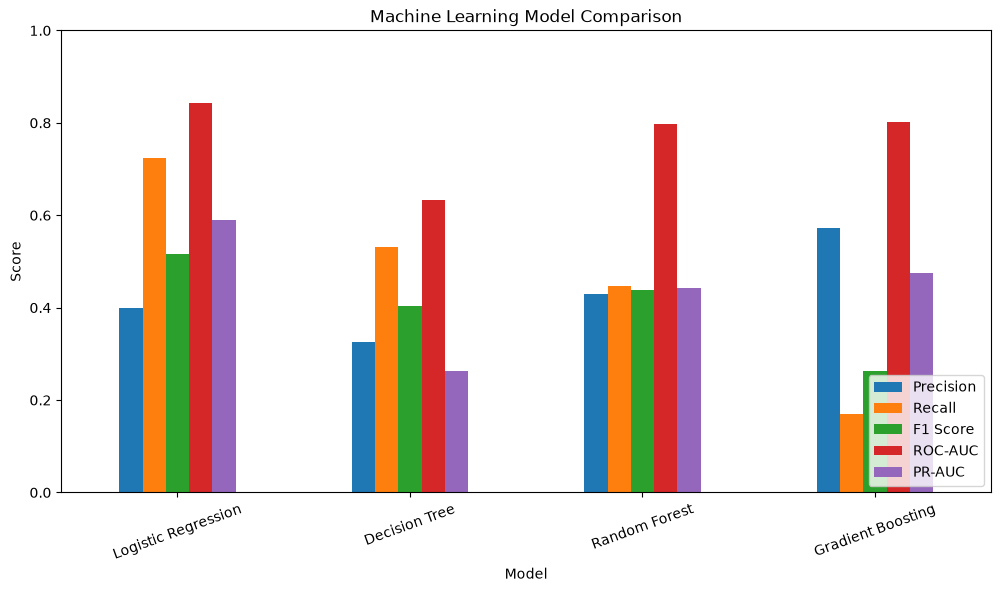

In [32]:
results_df.set_index('Model')[
    ['Precision', 'Recall', 'F1 Score', 'ROC-AUC', 'PR-AUC']
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Machine Learning Model Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.show()

In [33]:
results_df.sort_values(
    by=['F1 Score', 'Recall'],
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.782313,0.400000,0.723404,0.515152,0.842364,0.590378
2,Random Forest,0.816327,0.428571,0.446809,0.437500,0.798174,0.443108
1,Decision Tree,0.748299,0.324675,0.531915,0.403226,0.633302,0.262902
3,Gradient Boosting,0.846939,0.571429,0.170213,0.262295,0.801533,0.474635


In [34]:
best_model_name = results_df.sort_values(
    by='F1 Score',
    ascending=False
).iloc[0]['Model']

print("Best model based on F1 Score:", best_model_name)

Best model based on F1 Score: Logistic Regression


In [35]:
best_model = random_forest_pipeline

best_predictions = y_pred_rf
best_probabilities = y_prob_rf

In [36]:
print(
    classification_report(
        y_test,
        best_predictions,
        target_names=['Stayed', 'Left']
    )
)

              precision    recall  f1-score   support

      Stayed       0.89      0.89      0.89       247
        Left       0.43      0.45      0.44        47

    accuracy                           0.82       294
   macro avg       0.66      0.67      0.66       294
weighted avg       0.82      0.82      0.82       294



## 11. Confusion Matrix

The confusion matrix shows the number of:

- True Negatives
- False Positives
- False Negatives
- True Positives

False Negatives are particularly important in this project because
they represent employees who actually left but were incorrectly
predicted as staying.

## 12. ROC Curve

The ROC curve shows the trade-off between True Positive Rate
and False Positive Rate at different classification thresholds.

The Area Under the ROC Curve (ROC-AUC) summarizes the model's
ability to distinguish between employees who stay and employees
who leave.

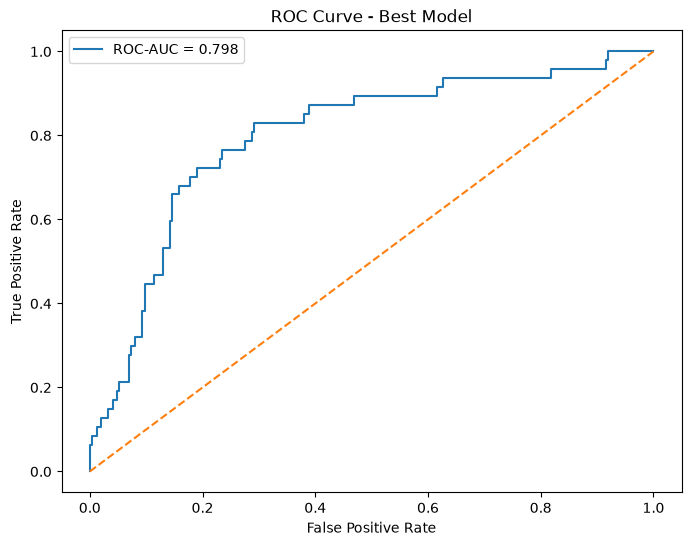

In [37]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    best_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'ROC-AUC = {roc_auc_score(y_test, best_probabilities):.3f}'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Best Model')
plt.legend()
plt.show()

## 13. Precision-Recall Curve

The Precision-Recall curve evaluates the trade-off between
precision and recall at different classification thresholds.

It is particularly useful when the positive class is relatively
rare, as is the case with employee attrition.

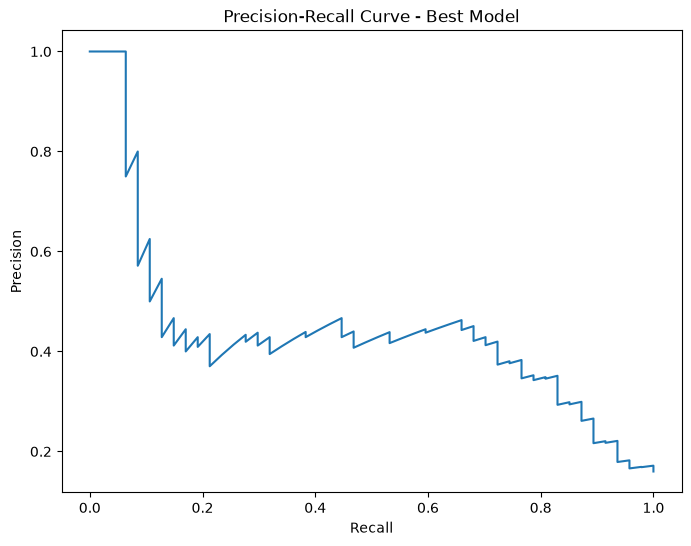

In [38]:
precision, recall, thresholds = precision_recall_curve(
    y_test,
    best_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Best Model')
plt.show()

In [39]:
model = best_model.named_steps['model']
preprocessor_fitted = best_model.named_steps['preprocessor']

In [40]:
feature_names = preprocessor_fitted.get_feature_names_out()

In [ ]:
precision, recall, thresholds = precision_recall_curve(
    y_test,
    best_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Best Model')
plt.show()

In [43]:
sample_employee = X_test.iloc[[0]]

sample_employee

,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AgeGroup,IncomeGroup,TenureGroup,RecentlyPromoted,JobLevelGroup,OverallSatisfaction,CompanyExperienceRatio
1061,24,Non-Travel,830,Sales,13,2,Life Sciences,4,Female,78,...,0,0,0,18-25,Low,0-2 Years,1,Entry Level,3.0,1.0


In [44]:
prediction = best_model.predict(sample_employee)[0]

probability = best_model.predict_proba(
    sample_employee
)[0][1]

print("Prediction:", prediction)
print(f"Attrition Probability: {probability:.2%}")

Prediction: 1
Attrition Probability: 74.05%


In [45]:
def risk_category(probability):

    if probability < 0.30:
        return 'Low Risk'
    elif probability < 0.60:
        return 'Medium Risk'
    else:
        return 'High Risk'

In [46]:
prediction_results = X_test.copy()

prediction_results['ActualAttrition'] = y_test.values

prediction_results['PredictedAttrition'] = best_predictions

prediction_results['AttritionProbability'] = best_probabilities

prediction_results['RiskLevel'] = [
    risk_category(prob)
    for prob in best_probabilities
]

In [47]:
prediction_results.head()

,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,IncomeGroup,TenureGroup,RecentlyPromoted,JobLevelGroup,OverallSatisfaction,CompanyExperienceRatio,ActualAttrition,PredictedAttrition,AttritionProbability,RiskLevel
1061,24,Non-Travel,830,Sales,13,2,Life Sciences,4,Female,78,...,Low,0-2 Years,1,Entry Level,3.0,1.000000,0,1,0.740548,High Risk
891,44,Travel_Rarely,1117,Research & Development,2,1,Life Sciences,1,Female,72,...,Low,6-10 Years,0,Entry Level,3.0,1.000000,0,0,0.198154,Low Risk
456,31,Travel_Rarely,688,Sales,7,3,Life Sciences,3,Male,44,...,Very High,3-5 Years,1,Mid Level,3.0,0.500000,0,0,0.279766,Low Risk
922,44,Travel_Rarely,1199,Research & Development,4,2,Life Sciences,3,Male,92,...,Very High,20+ Years,0,Senior Level,2.5,0.961538,0,0,0.074227,Low Risk
69,36,Travel_Rarely,318,Research & Development,9,3,Medical,4,Male,79,...,Medium,0-2 Years,1,Entry Level,2.5,0.500000,1,1,0.533722,Medium Risk


In [48]:
prediction_results.to_csv(
    '../data/attrition_predictions.csv',
    index=False
)

print("Prediction results saved successfully!")

Prediction results saved successfully!


## 14. Saving the Final Model

The complete preprocessing and machine learning pipeline is saved
using Joblib.

Saving the complete pipeline ensures that the same preprocessing
steps used during training are applied when making predictions
on new employee data.

In [49]:
joblib.dump(
    best_model,
    '../models/employee_attrition_model.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [50]:
loaded_model = joblib.load(
    '../models/employee_attrition_model.pkl'
)

In [51]:
loaded_prediction = loaded_model.predict(
    sample_employee
)[0]

loaded_probability = loaded_model.predict_proba(
    sample_employee
)[0][1]

print("Prediction:", loaded_prediction)
print(f"Probability: {loaded_probability:.2%}")

Prediction: 1
Probability: 74.05%


## 15. Conclusion

A complete machine learning workflow was developed for employee
attrition prediction.

The following classification algorithms were evaluated:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting

The models were evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC

Because employee attrition is an imbalanced classification problem,
greater importance was given to recall, precision, F1-score and
PR-AUC rather than accuracy alone.

The best-performing model was selected based on the evaluation results
and saved as a complete preprocessing and prediction pipeline.

The prediction results will be used in the next stages of the project
for SQL storage, Power BI visualization, and optional Streamlit
deployment.